# Olist 数据全景：从九张表到六个商业问题

这是 **数据熟悉与选题教程（draft）**，不是已经完成的 Briefing 或模型报告。适用于没看过这些数据、Python 和 pandas 刚入门的读者。

**你们已定 Olist，6 人各自探索一个角度；下面六个方向只是候选，不替你们锁题。** 每个人都先理解相同的表、统计单位和限制，再决定研究问题。

学完应能：辨认每张表的一行是什么；区分订单、商品明细与买家；安全连接两张表；解释支付、时间、评价的限制；为一个商业问题找出字段与验证办法。

阅读顺序：① 文件和表 → ② 字段与关系 → ③ 时间/金额/评价 → ④ 数据质量 → ⑤ 六个角度。第一次先读每节文字，再按 `Shift+Enter` 运行代码。Jupyter 的 Kernel → Restart Kernel and Run All Cells 可检验能否从头重做。

来源：[Olist 官方 Kaggle 数据集](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)。2026-09-30 下载；版本 2；许可 CC BY-NC-SA 4.0。平台更新时间 2021-10-01，不是业务发生年份。所有数字由本 Notebook 从 CSV 计算，所有解释与题目建议属于教学分析。

Canvas 最新行政信息未完成核验（当前浏览器跳转到登录）；本地 Guideline 与此前公告仅作暂存依据。这里不声明可提交，也不记录任何组员已经学会。

## 1. 从文件开始：先读，不清洗原件

CSV 是用逗号分隔的表格文件，DataFrame 是 pandas 在内存中表示表格的对象。原始文件放 `data/raw/`；本 Notebook **只读取原件，计算都在内存中**。

Python 的 `=` 把右边结果存到左边的变量名；`Path` 表示路径，路径之间的 `/` 是拼接目录；引号包住文字。`import` 导入工具；`pd` 是 pandas 的简称。`display` 把结果展示成表。

下面默认从 Notebook 所在目录启动。若报 `FileNotFoundError`，把 `WORK_DIR` 改成你电脑上本 Notebook 的完整目录；只改这一处，不需要把原始数据搬到别处。

In [1]:
from pathlib import Path
import json
import hashlib
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WORK_DIR = Path.cwd()
DATA_DIR = WORK_DIR / 'data' / 'raw'
assert DATA_DIR.is_dir(), f'找不到 {DATA_DIR}，请在首格设置 WORK_DIR'
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 65)
manifest = json.loads((WORK_DIR / 'data' / 'source-manifest.json').read_text(encoding='utf-8'))
print('数据目录：', DATA_DIR)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)

数据目录： D:\上课资料\CityU\IS6400_Business_Data_Analytics\assignment\graded\A06-group-project\work\data\raw
Python: 3.12.3 | pandas: 2.3.3


**怎么读输出：**它告诉你实际从哪个目录读取，以及运行环境版本。`assert` 是检查条件，不满足就停止，避免悄悄读取错误的数据。

**所以呢：**先确认来源位置，之后所有结论才能追溯到同一份数据。

### 1.1 先核验原始文件

SHA-256 是文件字节的指纹。我们把下载包中每个 CSV 的指纹记在来源清单里；相同指纹说明当前文件与保存的来源副本字节一致，**不说明内容没有业务错误**。

`for` 逐项重复处理；`item['name']` 从字典里取文件名；`.read_bytes()` 读取字节。下面的循环只检查，不改 CSV。

In [2]:
hash_checks = []
for item in manifest['files']:
    actual = hashlib.sha256((DATA_DIR / item['name']).read_bytes()).hexdigest()
    hash_checks.append({'文件': item['name'], '字节': item['bytes'], '指纹一致': actual == item['sha256']})
hash_table = pd.DataFrame(hash_checks)
display(hash_table)
assert hash_table['指纹一致'].all()

,文件,字节,指纹一致
0,olist_customers_dataset.csv,9033957,True
1,olist_geolocation_dataset.csv,61273883,True
2,olist_order_items_dataset.csv,15438671,True
3,olist_order_payments_dataset.csv,5777138,True
4,olist_order_reviews_dataset.csv,14451670,True
5,olist_orders_dataset.csv,17654914,True
6,olist_products_dataset.csv,2379446,True
7,olist_sellers_dataset.csv,174703,True
8,product_category_name_translation.csv,2613,True


9 个文件应全部为 True。来源包和原始 CSV 已备份，后续不要直接保存清洗结果覆盖这些文件。

**所以呢：**你和组员用同一版本，结果出现差异时才能检查计算方法，而不是猜谁拿错了文件。

## 2. 九张表不是九份独立数据集

可以把它看成围绕订单建立的档案：买家下单，订单包含商品，商品来自卖家，订单有支付记录、交付时间和评价。地理位置与品类翻译帮助解释这些记录。

下面 `FILES` 是“短名称 → 文件名”的字典。`pd.read_csv` 将 CSV 读成表；`dtype='string'` 保留邮编前导零。`tables[name]` 用短名称取出对应表，`.shape` 返回行数和列数。

In [3]:
FILES = {
    'orders': 'olist_orders_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'translation': 'product_category_name_translation.csv',
}
GRAIN = {
    'orders': '一笔订单', 'customers': '一个订单侧客户编号（不是独立自然人）',
    'items': '订单中的一条商品明细', 'payments': '订单的一条支付记录',
    'reviews': '一条评价记录（订单可能有多条）', 'products': '一个商品编号',
    'sellers': '一个卖家编号', 'geolocation': '邮编前缀对应的一条地理记录',
    'translation': '一个葡语品类名称的英文映射',
}
tables = {}
for name, filename in FILES.items():
    header = pd.read_csv(DATA_DIR / filename, nrows=0)
    postal_types = {c: 'string' for c in header.columns if 'zip_code_prefix' in c}
    tables[name] = pd.read_csv(DATA_DIR / filename, dtype=postal_types)
overview = pd.DataFrame([
    {'表': name, '行数': len(df), '列数': len(df.columns), '一行是什么': GRAIN[name]}
    for name, df in tables.items()
])
display(overview)

,表,行数,列数,一行是什么
0,orders,99441,8,一笔订单
1,customers,99441,5,一个订单侧客户编号（不是独立自然人）
2,items,112650,7,订单中的一条商品明细
3,payments,103886,5,订单的一条支付记录
4,reviews,99224,7,一条评价记录（订单可能有多条）
5,products,32951,9,一个商品编号
6,sellers,3095,4,一个卖家编号
7,geolocation,1000163,5,邮编前缀对应的一条地理记录
8,translation,71,2,一个葡语品类名称的英文映射


你应看到：订单和客户表各 99,441 行；商品明细 112,650 行；支付 103,886 行；评价 99,224 行；商品 32,951 行；卖家 3,095 行；地理位置 1,000,163 行；翻译 71 行。

不能把这些行数相加叫“订单量”。地理表一百万行也不代表一百万客户。

**所以呢：**分析的第一步是确定统计单位，例如研究延迟时通常以订单为单位，研究运费则先确认是明细运费还是订单合计。

## 3. 字段字典：列名和数据类型一起看

`dtype` 是程序读取的数据类型，不一定等于业务类型：邮编或 ID 即使看起来是数字，也不是拿来求平均的量。`object` 通常是文本；日期列最初也可能只是文本，要转成日期对象才能算时间差。

下面是全部 52 个“表—字段”位置（连接键在不同表重复出现）。含义依据发布方字段说明与实际表结构整理；主键等角色由本 Notebook 另行检验。快照字段没有完整历史版本，不能自动认定在过去每个预测日都可用。

In [4]:
FIELD_MEANINGS = {'order_id': '订单编号；订单表主键，其余订单相关表的连接键', 'customer_id': '订单侧客户编号；连接订单与客户表', 'customer_unique_id': '跨订单识别同一买家的匿名编号；不等于可确认的自然人身份', 'customer_zip_code_prefix': '买家邮编前缀；类别标识，应保留前导零', 'customer_city': '买家城市', 'customer_state': '买家州代码', 'order_status': '提取时的订单状态；不是订单确认时已知的最终结果', 'order_purchase_timestamp': '下单时间', 'order_approved_at': '支付/订单批准时间；建模时需选清预测时点', 'order_delivered_carrier_date': '交给承运方的实际时间', 'order_delivered_customer_date': '实际送达客户的时间', 'order_estimated_delivery_date': '预计交付日期；多为零点，比较时须明确按日期还是时间戳', 'order_item_id': '同一订单内的明细序号；需与 order_id 合作复合键', 'product_id': '商品编号', 'seller_id': '卖家编号', 'shipping_limit_date': '卖家交付物流的期限；不是实际发货时间', 'price': '商品明细金额，巴西雷亚尔 BRL；不是 Olist 的净营收', 'freight_value': '分配到该商品明细的运费 BRL；订单运费需汇总', 'payment_sequential': '订单内支付记录序号；不是购买次数', 'payment_type': '支付方式', 'payment_installments': '分期期数；不是支付表的行数', 'payment_value': '该支付记录金额 BRL', 'review_id': '评价编号；是否唯一需实际检查', 'review_score': '1–5 星评分', 'review_comment_title': '评价标题；缺失不代表没有评分', 'review_comment_message': '评价正文；未做语言识别或文本情感分析', 'review_creation_date': '评价问卷创建/发送相关日期；不是一定实际填写日期', 'review_answer_timestamp': '评价答复时间', 'product_category_name': '商品葡语品类名称', 'product_name_lenght': '商品名称长度（原始列名保留 lenght 拼写）', 'product_description_lenght': '商品描述长度（不是完整描述文本）', 'product_photos_qty': '商品图片数量', 'product_weight_g': '商品重量，克', 'product_length_cm': '商品长度，厘米', 'product_height_cm': '商品高度，厘米', 'product_width_cm': '商品宽度，厘米', 'seller_zip_code_prefix': '卖家邮编前缀', 'seller_city': '卖家城市', 'seller_state': '卖家州代码', 'geolocation_zip_code_prefix': '地理表邮编前缀；不是唯一键', 'geolocation_lat': '纬度', 'geolocation_lng': '经度', 'geolocation_city': '地理记录城市', 'geolocation_state': '地理记录州', 'product_category_name_english': '品类英文名称'}
field_rows = []
for name, df in tables.items():
    for col in df.columns:
        field_rows.append({'表': name, '字段': col, '读取类型': str(df[col].dtype),
                           '含义': FIELD_MEANINGS[col]})
field_dictionary = pd.DataFrame(field_rows)
with pd.option_context('display.max_rows', 60):
    display(field_dictionary)

,表,字段,读取类型,含义
0,orders,order_id,object,订单编号；订单表主键，其余订单相关表的连接键
1,orders,customer_id,object,订单侧客户编号；连接订单与客户表
2,orders,order_status,object,提取时的订单状态；不是订单确认时已知的最终结果
3,orders,order_purchase_timestamp,object,下单时间
4,orders,order_approved_at,object,支付/订单批准时间；建模时需选清预测时点
5,orders,order_delivered_carrier_date,object,交给承运方的实际时间
6,orders,order_delivered_customer_date,object,实际送达客户的时间
7,orders,order_estimated_delivery_date,object,预计交付日期；多为零点，比较时须明确按日期还是时间戳
8,customers,customer_id,object,订单侧客户编号；连接订单与客户表
9,customers,customer_unique_id,object,跨订单识别同一买家的匿名编号；不等于可确认的自然人身份


**怎么读：**`BILL` 等其他数据集的字段没有出现在这里，Olist 也没有利润、曝光、购物车、客服干预日志。分析不能凭需要补出不存在的字段。

**所以呢：**现在可以先区分现成变量、需要计算的变量，以及这个数据集根本不支持的变量。

## 4. 主键与连接：先弄清楚“一对几”

主键是能唯一辨认一行的字段；复合键用两个字段一起辨认。外键是指向另一张表的编号。`is_unique` 检查单列是否唯一，`duplicated` 检查重复。

关系地图（箭头表示去找对应信息，不是复制数据）：

| 起点 | 连接键 | 对应信息 | 关系 |
|---|---|---|---|
| orders | customer_id | customers | 本版本一对一；同一买家可有多个 customer_id |
| orders | order_id | items / payments / reviews | 一对零或多 |
| items | product_id / seller_id | products / sellers | 多对一 |
| products | product_category_name | translation | 多对一，需检查匹配缺口 |
| customers / sellers | 邮编前缀 | geolocation | 地理表前缀有重复，不能直接当多对一 |

买家在数据中的可追踪身份用 `customer_unique_id`。同一买家第二次下单，不应因为新 `customer_id` 被当作新买家。

In [5]:
orders = tables['orders'].copy()
customers = tables['customers']
items = tables['items']
payments = tables['payments']
reviews = tables['reviews']
checks = pd.Series({
    '订单号唯一': orders.order_id.is_unique,
    '客户表 customer_id 唯一': customers.customer_id.is_unique,
    '商品号唯一': tables['products'].product_id.is_unique,
    '卖家号唯一': tables['sellers'].seller_id.is_unique,
    '订单+明细序号唯一': not items.duplicated(['order_id','order_item_id']).any(),
    '订单+支付序号唯一': not payments.duplicated(['order_id','payment_sequential']).any(),
    '评价 review_id 唯一': reviews.review_id.is_unique,
    '地理邮编前缀唯一': tables['geolocation'].geolocation_zip_code_prefix.is_unique,
})
display(checks.to_frame('检查结果'))
print('customer_id 数：', customers.customer_id.nunique())
print('customer_unique_id 数：', customers.customer_unique_id.nunique())

,检查结果
订单号唯一,True
客户表 customer_id 唯一,True
商品号唯一,True
卖家号唯一,True
订单+明细序号唯一,True
订单+支付序号唯一,True
评价 review_id 唯一,False
地理邮编前缀唯一,False


customer_id 数： 99441
customer_unique_id 数： 96096


你会看到 99,441 个订单侧客户编号对应 **96,096 个买家编号**；评价编号和地理邮编前缀也不能都直接当唯一键。不要遇到重复就整表去重，否则可能删掉业务上不同的记录。

**所以呢：**接下来用一笔真实订单，观察错误连接如何让金额翻倍。

### 4.1 一笔订单的连接陷阱

`groupby('order_id').size()` 数每笔订单有多少行；`merge` 按键连接；`query` 按条件挑行；`iloc[0]` 取第一项。示例选择同时有多条商品与支付记录的订单，只展示这一笔，不运行全库的错误连接。

In [6]:
counts = pd.concat([
    items.groupby('order_id').size().rename('商品明细数'),
    payments.groupby('order_id').size().rename('支付记录数'),
], axis=1)
example_id = counts.query('商品明细数 > 1 and 支付记录数 > 1').index[0]
example_items = items.loc[items.order_id.eq(example_id), ['order_id','order_item_id','price']]
example_payments = payments.loc[payments.order_id.eq(example_id), ['order_id','payment_sequential','payment_value']]
wrong_join = example_items.merge(example_payments, on='order_id')
display(wrong_join)
print(f'商品原金额：{example_items.price.sum():.2f} | 错误连表后：{wrong_join.price.sum():.2f}')
print(f'支付原金额：{example_payments.payment_value.sum():.2f} | 错误连表后：{wrong_join.payment_value.sum():.2f}')

,order_id,order_item_id,price,payment_sequential,payment_value
0,03ecec245220b63fd7f68c1737ba99ba,1,189.0,2,56.39
1,03ecec245220b63fd7f68c1737ba99ba,1,189.0,1,319.34
2,03ecec245220b63fd7f68c1737ba99ba,2,109.9,2,56.39
3,03ecec245220b63fd7f68c1737ba99ba,2,109.9,1,319.34


商品原金额：298.90 | 错误连表后：597.80
支付原金额：375.73 | 错误连表后：751.46


这笔订单 2 条商品 × 2 条支付变成 4 行，每条记录被复制。连接成功不等于统计正确。

**正确办法：**先把商品、支付分别汇总成“一行一订单”，再连接。`agg` 指定汇总；`sum` 求和，`nunique` 数不同编号；`validate='one_to_one'` 要求两边键都唯一。`how='left'` 保留所有订单，未匹配字段会是缺失值，不能自动填成 0。

In [7]:
item_order = items.groupby('order_id').agg(
    item_rows=('order_item_id','size'),
    item_value=('price','sum'),
    freight_value=('freight_value','sum'),
    seller_count=('seller_id','nunique'),
).reset_index()
payment_order = payments.groupby('order_id').agg(
    payment_value=('payment_value','sum'),
    payment_records=('payment_sequential','size'),
).reset_index()
order_view = orders.merge(item_order, on='order_id', how='left', validate='one_to_one')
order_view = order_view.merge(payment_order, on='order_id', how='left', validate='one_to_one')
assert len(order_view) == len(orders) and order_view.order_id.is_unique
display(order_view.loc[order_view.order_id.eq(example_id),
                       ['order_id','item_rows','item_value','freight_value','payment_value','payment_records']])
print('连接前后均为', len(order_view), '笔订单')

,order_id,item_rows,item_value,freight_value,payment_value,payment_records
84526,03ecec245220b63fd7f68c1737ba99ba,2.0,298.9,76.83,375.73,2.0


连接前后均为 99441 笔订单


这里只生成内存中的演示表，不保存清洗后的完整数据。评价需要单独确定选择规则，地理位置需要先确定邮编聚合方法，本节没有强行拼成一张万能宽表。

**所以呢：**六个人可以各自选题，但订单单位与连接规则必须一致。

## 5. 数据质量：缺失不都是错误，重复不都应删除

`.isna().sum()` 数缺失值；除以行数是缺失比例。`.nunique()` 数不同非空取值。缺失评论正文不等于没有评分；缺少送达时间可能和订单状态有关。先解释，再决定清洗规则。

In [8]:
quality_rows = []
for name, df in tables.items():
    for col in df:
        quality_rows.append({'表':name, '字段':col, '缺失数':int(df[col].isna().sum()),
                             '缺失率%':100*df[col].isna().mean(), '不同非空值':df[col].nunique()})
quality = pd.DataFrame(quality_rows)
display(quality.loc[quality['缺失数'].gt(0)].round({'缺失率%':2}))
print('地理表完整重复行：', tables['geolocation'].duplicated().sum())
print('地理表不同邮编前缀：', tables['geolocation'].geolocation_zip_code_prefix.nunique())

,表,字段,缺失数,缺失率%,不同非空值
4,orders,order_approved_at,160,0.16,90733
5,orders,order_delivered_carrier_date,1783,1.79,81018
6,orders,order_delivered_customer_date,2965,2.98,95664
28,reviews,review_comment_title,87656,88.34,4527
29,reviews,review_comment_message,58247,58.70,36159
33,products,product_category_name,610,1.85,73
34,products,product_name_lenght,610,1.85,66
35,products,product_description_lenght,610,1.85,2960
36,products,product_photos_qty,610,1.85,19
37,products,product_weight_g,2,0.01,2204


地理表完整重复行： 261831
地理表不同邮编前缀： 19015


地理表有 **261,831 条完整重复行**和 **19,015 个不同邮编前缀**。即使删除完整重复行，一个邮编仍可能有多个坐标；邮编位置是近似代表位置，不是客户精确地址。

**所以呢：**做区域分析可以先用州级别；是否加入地图取决于研究问题，而不是因为数据里恰好有经纬度。

### 5.1 检查连接缺口

`isin` 判断编号是否存在于另一表，前面的 `~` 表示取反；`sum()` 数出缺口。没有匹配记录不等于字段值为零。

In [9]:
link_checks = pd.Series({
    '订单缺客户记录': (~orders.customer_id.isin(customers.customer_id)).sum(),
    '订单无商品明细': (~orders.order_id.isin(items.order_id)).sum(),
    '订单无支付记录': (~orders.order_id.isin(payments.order_id)).sum(),
    '订单无评价记录': (~orders.order_id.isin(reviews.order_id)).sum(),
    '明细找不到订单': (~items.order_id.isin(orders.order_id)).sum(),
    '明细找不到商品': (~items.product_id.isin(tables['products'].product_id)).sum(),
    '明细找不到卖家': (~items.seller_id.isin(tables['sellers'].seller_id)).sum(),
})
display(link_checks.to_frame('数量'))
print('一笔订单多条评价：', reviews.groupby('order_id').size().gt(1).sum())
print('一笔订单多个卖家：', items.groupby('order_id').seller_id.nunique().gt(1).sum())

,数量
订单缺客户记录,0
订单无商品明细,775
订单无支付记录,1
订单无评价记录,768
明细找不到订单,0
明细找不到商品,0
明细找不到卖家,0


一笔订单多条评价： 547
一笔订单多个卖家： 1278


应看到 **775 笔订单无明细、1 笔无支付、768 笔无评价**；有 **547 笔订单多条评价、1,278 笔订单多个卖家**。这些都影响分析范围。多卖家订单的一条订单评价不能随意完全归咎于其中某一个卖家。

**所以呢：**报告必须列出样本排除数量与理由，不能只说“完成数据清洗”。

## 6. 时间与状态：数据不是完整的每月市场统计

`pd.to_datetime` 将时间文本转换成时间对象；`errors='coerce'` 把无法解释的值标为 NaT（时间缺失），下面同时核对是否出现新增解析失败。`.dt.to_period('M')` 将每笔订单归到月份。

下单范围： 2016-09-04 21:15:19 至 2018-10-17 17:30:18


,订单数
2016-09,4
2016-10,324
2016-11,0
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


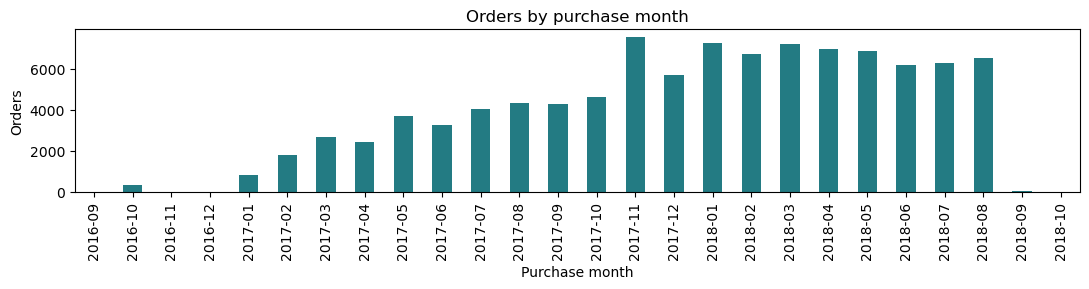

In [10]:
date_cols = ['order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
             'order_delivered_customer_date','order_estimated_delivery_date']
for col in date_cols:
    old_missing = orders[col].isna().sum()
    orders[col] = pd.to_datetime(orders[col], errors='coerce')
    assert orders[col].isna().sum() == old_missing, f'{col} 出现解析失败'
print('下单范围：', orders.order_purchase_timestamp.min(), '至', orders.order_purchase_timestamp.max())
monthly = orders.groupby(orders.order_purchase_timestamp.dt.to_period('M')).size()
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq='M'),fill_value=0)
display(monthly.rename('订单数').to_frame())
ax = monthly.plot.bar(figsize=(11,3), color='#237b83')
ax.set_title('Orders by purchase month'); ax.set_xlabel('Purchase month'); ax.set_ylabel('Orders')
plt.tight_layout(); plt.show()

日期边界为 **2016-09-04 至 2018-10-17**。但 2018 年 9 月只有 **16 笔**，10 月只有 **4 笔**；2016 年也稀疏。图的横轴是下单月份，纵轴是记录数，末尾骤降首先提示样本覆盖限制，不能直接叫业务崩盘。图中的 0 仅表示提取数据内没有记录，不保证企业当月没有订单。

**所以呢：**研究时间趋势或训练测试划分前，先挑选有足够覆盖且标签成熟的区间，再解释排除的边界月份。

In [11]:
status_counts = orders.order_status.value_counts()
display(pd.DataFrame({'订单数':status_counts,'占全部订单%':status_counts/len(orders)*100}).round(2))

,订单数,占全部订单%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


共有 **96,478 笔状态为 delivered 的订单**。其余含 shipped、canceled、unavailable 等；不能把没有送达记录的订单当成“没有延迟”。当前订单状态是提取时结果，不是下单时能预知的信息。

**所以呢：**“全部订单”和“可评价送达的订单”是两个分母。

## 7. 交付延迟：同一个词必须给明确口径

预计交付字段通常存日期的零点。例如预计 5 月 10 日，实际 5 月 10 日下午送达：按日历日期算没有晚，直接比较完整时间戳却会晚。

本节并列展示两种口径，**不是代替你们或老师规定标签**。示例主口径采用实际送达日期晚于预计日期；只统计 delivered 且两日期齐全的订单。`normalize()` 去掉时分秒但保留日期，`gt()` 比较大于；布尔值 True 的均值就是比例。

In [12]:
delivered = orders.loc[orders.order_status.eq('delivered')].copy()
valid_delivery = delivered.dropna(subset=['order_delivered_customer_date','order_estimated_delivery_date']).copy()
late_calendar = valid_delivery.order_delivered_customer_date.dt.normalize().gt(
    valid_delivery.order_estimated_delivery_date.dt.normalize())
late_timestamp = valid_delivery.order_delivered_customer_date.gt(valid_delivery.order_estimated_delivery_date)
display(pd.DataFrame({
    '口径':['晚于预计日期','晚于完整预计时间戳'],
    '延迟订单数':[int(late_calendar.sum()),int(late_timestamp.sum())],
    '分母':[len(valid_delivery)]*2,
    '比例%':[100*late_calendar.mean(),100*late_timestamp.mean()],
}).round(4))
print('delivered 中缺少必要日期：',len(delivered)-len(valid_delivery))

,口径,延迟订单数,分母,比例%
0,晚于预计日期,6534,96470,6.7731
1,晚于完整预计时间戳,7826,96470,8.1124


delivered 中缺少必要日期： 8


应得到 **6,534 / 96,470 ≈ 6.7731%** 与 **7,826 / 96,470 ≈ 8.1124%**。分母缺了 delivered 中的 8 笔日期不全订单。差异不是模型造成的，而是标签定义造成的。

若六人各自研究，也必须在汇报中说清延迟、金额、复购各自口径。不要只贴一个百分数。

**所以呢：**业务定义在建模之前，标签不清楚时模型再精确也无法解释。

## 8. 金额：成交、支付、运费与平台营收不是同一个量

`price` 与 `freight_value` 在明细表；`payment_value` 在支付表。以 BRL（巴西雷亚尔）为单位。下面计算全表总和，包含不同订单状态，**不是仅已交付订单金额，更不是扣退款后的净收入或平台利润**。

In [13]:
amounts = pd.Series({
    '全明细商品金额': items.price.sum(),
    '全明细运费': items.freight_value.sum(),
    '商品金额加运费': items.price.sum()+items.freight_value.sum(),
    '全支付记录金额': payments.payment_value.sum(),
})
display(amounts.round(2).to_frame('BRL'))
amount_check = order_view.dropna(subset=['item_value','freight_value','payment_value']).copy()
amount_check['difference'] = amount_check.payment_value - amount_check.item_value - amount_check.freight_value
print('两侧金额齐全的订单：',len(amount_check))
print('绝对差额大于 0.01 BRL 的订单：',(amount_check.difference.abs()>0.010001).sum())

,BRL
全明细商品金额,13591643.70
全明细运费,2251909.54
商品金额加运费,15843553.24
全支付记录金额,16008872.12


两侧金额齐全的订单： 98665


绝对差额大于 0.01 BRL 的订单： 303


全明细商品金额 **13,591,643.70 BRL**，运费 **2,251,909.54 BRL**，全支付金额 **16,008,872.12 BRL**。总额不完全相等，需逐订单检查记录覆盖、支付形式与异常，而不是强制调平。

**所以呢：**如果选择运费或支付角度，可以研究结构和关联，但没有毛利、平台抽成和完整退款信息，就不能称为盈利分析。

## 9. 评价：评分不等于文本，也不一定一单一评

下面 `.value_counts().sort_index()` 按星级统计。分母是评价行数，不是全部订单，更不是平台所有消费者。

,评价行数,占评价记录%
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


评价均分（记录口径）： 4.0864
正文非空比例： 41.3 %


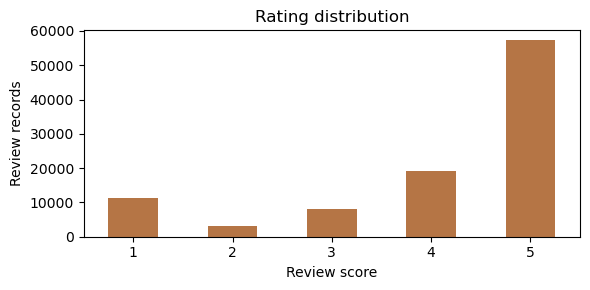

In [14]:
rating_counts = reviews.review_score.value_counts().sort_index()
display(pd.DataFrame({'评价行数':rating_counts,'占评价记录%':100*rating_counts/len(reviews)}).round(2))
print('评价均分（记录口径）：',round(reviews.review_score.mean(),4))
print('正文非空比例：',round(100*reviews.review_comment_message.notna().mean(),2),'%')
ax=rating_counts.plot.bar(figsize=(6,3),color='#b57545',rot=0)
ax.set_xlabel('Review score'); ax.set_ylabel('Review records'); ax.set_title('Rating distribution')
plt.tight_layout(); plt.show()

五星 **57,328 条**、一星 **11,424 条**。大量有评分记录没有正文；情感分析只能覆盖有文本的子集，还需核语言与自动分类质量。不能把空正文当作中性评论。

如果研究延迟与低评分，需要先给多评价订单定规则（例如按时间选一条，并用其他规则作敏感性检查）；物流、品类、价格等也可能相互关联，所以观察到相关性不能直接说“延迟导致差评”。

**所以呢：**“评价记录占比”和“订单低评分比例”必须分清，后者需要先把评价统一到订单层面。

## 10. 买家复购：这个数据集的观察边界

先按 customer_id 给每笔订单找 customer_unique_id，再数每个买家有几笔订单。本节包含全部订单状态；若研究有效购买复购，应重新限定有效订单，不能直接复用这个数。

In [15]:
buyer_orders = orders[['order_id','customer_id']].merge(
    customers[['customer_id','customer_unique_id']],on='customer_id',validate='one_to_one')
buyer_counts = buyer_orders.groupby('customer_unique_id').size()
print('数据中买家编号数：',len(buyer_counts))
print('出现至少两笔订单的买家：',int(buyer_counts.gt(1).sum()))
print('比例：',round(100*buyer_counts.gt(1).mean(),4),'%')
display(buyer_counts.value_counts().sort_index().rename('买家数').to_frame())

数据中买家编号数： 96096
出现至少两笔订单的买家： 2997
比例： 3.1188 %


,买家数
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


**96,096 个买家编号中，2,997 个有至少两笔订单，约 3.1188%。** 这是数据内、全部状态下的重复下单观察；不能称为 Olist 全市场真实复购率，也不能把没有第二次记录等同流失。末期客户观察时间较短，平台外购买也不可见。

**所以呢：**比起零售两年完整交易类数据，Olist 的客户留存题需要更谨慎；物流与评价可能更容易得到有足够样本的结果。

## 11. 六个人各自可探索什么

你们计划每人先做一个角度。建议用相同模板比较候选：决策者、业务问题、统计单位、目标、字段、简单对照、评价方式、边界。下面都是候选方案，没有任何一个被预设为最终组题。

| 角度 | 明确问题 | 主要表与粒度 | 可验证结果 | 最大限制 |
|---|---|---|---|---|
| 交付风险 | 订单确认时，能否识别以后晚于承诺日期的订单？ | orders/items/products/sellers/customers；订单 | 时间留出上的延迟识别、复核名单覆盖 | 排除未来交付状态，历史信息按当时可得构造 |
| 客户体验 | 哪些订单特征与低评分相关？ | reviews+orders+items；订单 | 低评分关联、不同口径下稳定性 | 多评规则、未评选择、不能声称因果 |
| 运费与区域 | 哪些地区/品类的运费负担高，交付又慢？ | items/products/customers/sellers；先明细再订单或区域 | 运费占比与交付分布、同类对照 | 不知道真实物流成本或实际路线，不能算利润 |
| 卖家履约 | 哪些卖家在相近订单条件下值得优先排查？ | sellers/items/orders；卖家及订单 | 样本量充分的履约差异、未来时期检验 | 多卖家订单归属、少样本排名不稳定 |
| 品类与需求结构 | 哪些品类的订单金额/记录量变化值得关注？ | orders/items/products/translation；品类月份 | 时间走势、结构变化及边界月份检查 | 不等于全市场需求，没有库存/曝光分母 |
| 支付与分期 | 不同金额和品类的订单使用哪些支付与分期方式？ | payments+订单聚合items；订单 | 使用结构及控制条件后的关联 | 分期不是多行支付，没有信贷损失，不能称提高转化 |

可以额外考虑买家复购，但上节提示其观察样本稀疏，需要先验证可行性。

**预测任务**必须在未来结果发生前取输入；**事后解释任务**可使用已发生的交付结果，但不得伪装成提前预测。每个角度都应说明一个最简单的比较对象，而不是直接列模型名称。

## 12. 四个理解检查

先自己回答，再展开。文件跑通不代表你本人已经掌握；本轮不把这些题记为你已完成。

1. 一笔订单有 3 条商品和 2 条支付，直接按订单号连接会有几行？
2. 为什么 99,441 行客户表不等于 99,441 个独立买家？
3. 预计 5 月 10 日送达、实际当天 15:00 送达，按两个口径分别是否延迟？
4. 没有评价正文的订单能否标成“不满意”？没有第二笔订单能否标成“流失”？

<details><summary>展开参考答案</summary>

1. 3×2＝6 行，每条商品复制两次、每条支付复制三次。先各自按订单汇总，再用唯一键连接。
2. customer_id 是订单侧客户编号；跨订单的匿名买家用 customer_unique_id。需明确统计层级。
3. 按日历日没有晚；若预计字段为当天零点，直接比较完整时间戳会算晚。因此报告必须明确标签口径。
4. 都不能。空正文可能仍有五星评分；没有复购记录可能因为观察窗口短或发生在数据覆盖范围之外。

</details>

**下一步：**先挑一个你最想解释的现象，用一两句话写出“谁、什么决策、何时知道什么”。之后再单独做该方向的分析 Notebook；不要把六套未经论证的方法都堆到同一份 3 分钟汇报里。

## 13. 原件保护与复现检查

最后重新计算文件指纹，确认本次运行没有修改原始数据。本 Notebook 不联网、不写 CSV、不训练模型，也不导出提交件。

In [16]:
for item in manifest['files']:
    assert hashlib.sha256((DATA_DIR/item['name']).read_bytes()).hexdigest() == item['sha256']
print('9 个原始 CSV 指纹全部保持一致。')
print('Notebook 执行完成；本人学习、选题决定与 Canvas 提交仍须分别确认。')

9 个原始 CSV 指纹全部保持一致。
Notebook 执行完成；本人学习、选题决定与 Canvas 提交仍须分别确认。
